In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

df = pd.read_csv("AirQuality_Clean.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Saving AirQuality_Clean.csv to AirQuality_Clean.csv
Dataset loaded successfully!
Dataset shape: (9357, 14)


,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,DateTime
0,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,2004-03-10 18:00:00
1,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,2004-03-10 19:00:00
2,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,2004-03-10 20:00:00
3,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,2004-03-10 21:00:00
4,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,2004-03-10 22:00:00


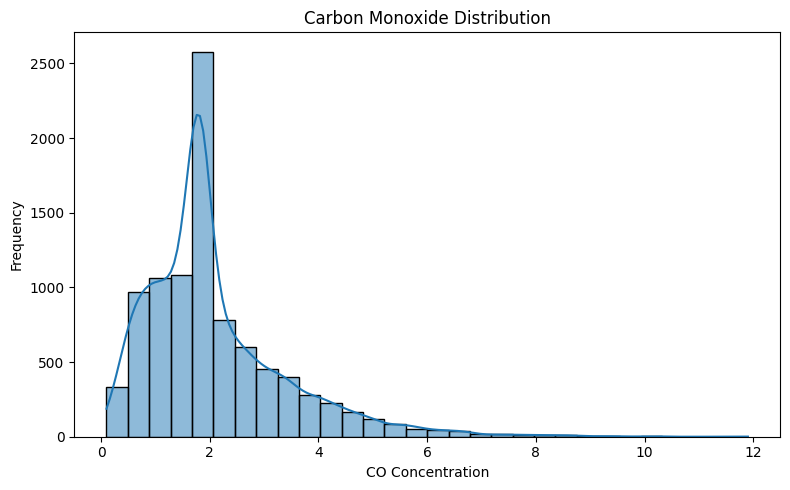

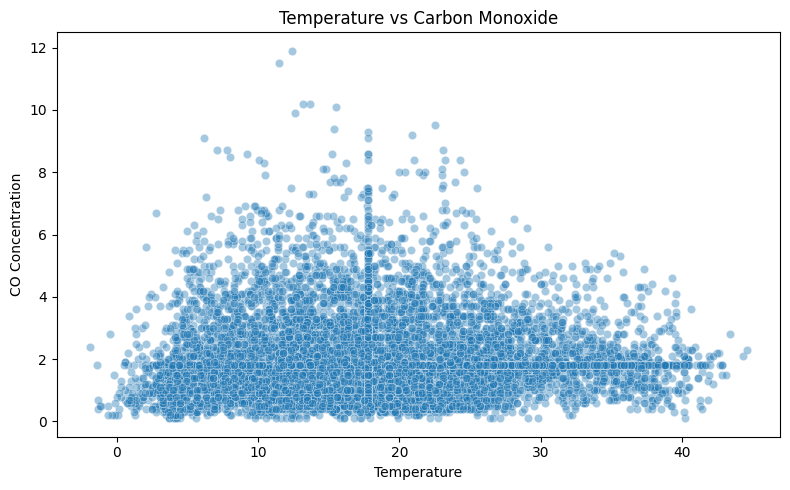

In [2]:

# Graph 1: Carbon monoxide distribution
plt.figure(figsize=(8, 5))

sns.histplot(df["CO(GT)"], bins=30, kde=True)

plt.title("Carbon Monoxide Distribution")
plt.xlabel("CO Concentration")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig("CO_Distribution.png")
plt.show()

# Graph 2: Temperature vs Carbon Monoxide
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="T",
    y="CO(GT)",
    alpha=0.4
)

plt.title("Temperature vs Carbon Monoxide")
plt.xlabel("Temperature")
plt.ylabel("CO Concentration")

plt.tight_layout()
plt.savefig("Temperature_vs_CO.png")
plt.show()


In [3]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

features = ["T", "RH", "AH"]
target = "CO(GT)"

X = df[features]
y = df[target]

# Use chronological order to separate training and testing
split = int(len(df) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]
y_train = y.iloc[:split]
y_test = y.iloc[split:]

regression_model = LinearRegression()
regression_model.fit(X_train, y_train)

predictions = regression_model.predict(X_test)

print("Regression Results")
print("Mean Absolute Error:",
      mean_absolute_error(y_test, predictions))
print("R² Score:",
      r2_score(y_test, predictions))


Regression Results
Mean Absolute Error: 1.0724426751086749
R² Score: -0.029180582891460416


Classification Accuracy: 0.594551282051282
              precision    recall  f1-score   support

         Low       0.60      0.99      0.74      1112
        High       0.53      0.01      0.02       760

    accuracy                           0.59      1872
   macro avg       0.56      0.50      0.38      1872
weighted avg       0.57      0.59      0.45      1872



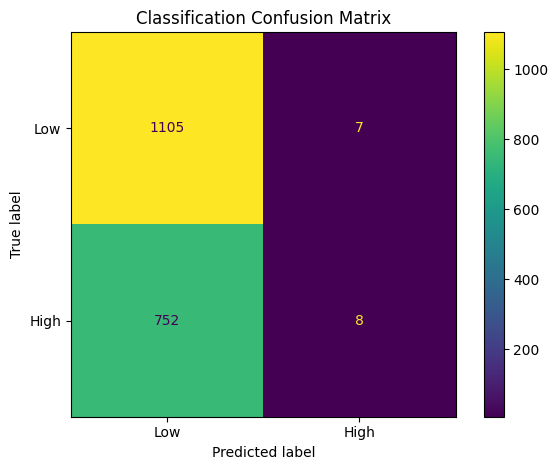

In [4]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Define threshold using training data only
threshold = y_train.median()

y_train_class = (y_train > threshold).astype(int)
y_test_class = (y_test > threshold).astype(int)

classification_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

classification_model.fit(X_train, y_train_class)

class_predictions = classification_model.predict(X_test)

print("Classification Accuracy:",
      accuracy_score(y_test_class, class_predictions))

print(classification_report(
    y_test_class,
    class_predictions,
    target_names=["Low", "High"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test_class,
    class_predictions,
    display_labels=["Low", "High"]
)

plt.title("Classification Confusion Matrix")
plt.tight_layout()
plt.savefig("Classification_Results.png")
plt.show()


In [5]:

from google.colab import files

files.download("CO_Distribution.png")
files.download("Temperature_vs_CO.png")
files.download("Classification_Results.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>